# 🚗 RUN 3: MobilePIXORNeXt (Smooth-L1 + IQA Control, 50 Epochs)

Pipeline huấn luyện đối chứng **Smooth-L1 + IQA** trên kiến trúc chuẩn depth `[3, 4, 2]` để cung cấp đối chứng chuẩn xác cho Table 9 (Loss Ablation).


In [ ]:
# ==============================================================================
# Cell 1: Environment Setup, Mounting & Dependency Verification
# ==============================================================================
# Code is strictly managed on GitHub and cloned/pulled to local Colab disk (/content/Lidar).
# Google Drive is used ONLY for persistent checkpoints and dataset archives.
# ==============================================================================
import os
import sys
import math
import json
import shlex
import shutil
import hashlib
import tempfile
import importlib
from pathlib import Path
import torch

q = shlex.quote

GIT_REPO_URL = "https://github.com/danhyoyo/Lidar.git"
GIT_BRANCH = "research/mobilepixornext-under1m-paper"

# 1. Detect if running inside Google Colab
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    print("Detected Google Colab environment.")
    print("Mounting Google Drive for persistent artifacts & dataset archives...")
    from google.colab import drive
    drive.mount("/content/drive")

    # Codebase lives STRICTLY on Colab local disk, cloned/updated from GitHub:
    REPO_ROOT = Path("/content/Lidar").resolve()
    if not (REPO_ROOT / ".git").is_dir():
        print(f"Cloning branch '{GIT_BRANCH}' from GitHub into {REPO_ROOT}...")
        !git clone -b {q(GIT_BRANCH)} {q(GIT_REPO_URL)} {q(str(REPO_ROOT))}
    else:
        print(f"Updating repository from GitHub: {REPO_ROOT}...")
        !git -C {q(str(REPO_ROOT))} fetch origin {q(GIT_BRANCH)}
        !git -C {q(str(REPO_ROOT))} checkout {q(GIT_BRANCH)}
        !git -C {q(str(REPO_ROOT))} pull origin {q(GIT_BRANCH)}

    print("✓ Active Git commit on Colab:")
    !git -C {q(str(REPO_ROOT))} log -1 --oneline

    DEFAULT_REPO_DIR = (REPO_ROOT / "Code").resolve()
    if not (DEFAULT_REPO_DIR / "configs/config.json").is_file():
        raise FileNotFoundError(f"Cannot find configs/config.json in {DEFAULT_REPO_DIR}")

    print("Verifying requirements on Colab...")
    requirements_file = DEFAULT_REPO_DIR / "requirements-kitti.txt"
    if requirements_file.is_file():
        !pip install -q -r {q(str(requirements_file))}

    # Google Drive: Checkpoints and Dataset Archives ONLY (NO CODE ON DRIVE)
    DRIVE_BASE = Path("/content/drive/MyDrive/lidar_project").resolve()
    DEFAULT_ARTIFACT_ROOT = (DRIVE_BASE / "artifacts").resolve()
    DEFAULT_DRIVE_RAW_DIR = Path("/content/drive/MyDrive/KITTI_DATASET_ZIP").resolve()

    # Fast local scratch SSD for extraction and preprocessing
    DEFAULT_RAW_ROOT = Path("/content/kitti_raw").resolve()
    DEFAULT_PROCESSED_ROOT = Path("/content/kitti_processed").resolve()

else:
    print("Running in local workstation environment.")
    REPO_ROOT = Path.cwd().resolve()
    if (REPO_ROOT / "Code/configs/config.json").is_file():
        DEFAULT_REPO_DIR = (REPO_ROOT / "Code").resolve()
    elif (REPO_ROOT / "configs/config.json").is_file():
        DEFAULT_REPO_DIR = REPO_ROOT
    else:
        DEFAULT_REPO_DIR = REPO_ROOT

    DEFAULT_ARTIFACT_ROOT = (DEFAULT_REPO_DIR / "artifacts").resolve()
    DEFAULT_DRIVE_RAW_DIR = (DEFAULT_REPO_DIR / "data/kitti/raw").resolve()
    DEFAULT_RAW_ROOT = (DEFAULT_REPO_DIR / "data/kitti/raw").resolve()
    DEFAULT_PROCESSED_ROOT = (DEFAULT_REPO_DIR / "data/kitti/processed").resolve()


# 2. Base directory configuration
REPO_DIR = DEFAULT_REPO_DIR
ARTIFACT_ROOT = DEFAULT_ARTIFACT_ROOT
DRIVE_RAW_DIR = DEFAULT_DRIVE_RAW_DIR
RAW_KITTI_ROOT = DEFAULT_RAW_ROOT
PROCESSED_DATASET_DIR = DEFAULT_PROCESSED_ROOT
RAW_TRAINING = RAW_KITTI_ROOT if RAW_KITTI_ROOT.name == "training" else RAW_KITTI_ROOT / "training"

ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
RAW_KITTI_ROOT.mkdir(parents=True, exist_ok=True)
PROCESSED_DATASET_DIR.mkdir(parents=True, exist_ok=True)
RAW_TRAINING.mkdir(parents=True, exist_ok=True)


# 3. Path & Module Configuration
os.chdir(REPO_DIR)
pipeline_dir = REPO_DIR / "tools/kitti_training_pipeline"

# Clean stale module caches
for name in list(sys.modules):
    if any(name == p or name.startswith(p + ".") for p in ("detector", "core", "tools", "common", "utils_1", "notebook_config", "notebook_workflow")):
        del sys.modules[name]

importlib.invalidate_caches()

# Ensure local REPO_DIR has highest priority in sys.path
paths = [
    str(pipeline_dir),
    str(REPO_DIR / "detector/core/datasets"),
    str(REPO_DIR / "detector"),
    str(REPO_DIR),
]
for p in reversed(paths):
    if p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)

os.environ["PYTHONUNBUFFERED"] = "1"

from common import configure_detector_imports
configure_detector_imports(REPO_DIR / "detector")


# 4. Device & Hardware Inspection
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Working Directory (Code): {REPO_DIR}")
print(f"Artifacts (Drive)       : {ARTIFACT_ROOT}")
print(f"Dataset Archives (Drive): {DRIVE_RAW_DIR}")
print(f"Local Fast Raw Dir      : {RAW_KITTI_ROOT}")
print(f"Local Processed Dir     : {PROCESSED_DATASET_DIR}")
print(f"Execution Device        : {DEVICE}")

if DEVICE == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    bf16_supported = torch.cuda.is_bf16_supported()

    print(f"GPU Hardware            : {gpu_name} ({vram_gb:.2f} GB VRAM)")
    print(f"BF16 Precision Support  : {'YES' if bf16_supported else 'NO'}")



Detected Google Colab environment. Mounting Google Drive...
Mounted at /content/drive
Using repository found on Google Drive: /content/drive/MyDrive/Lidar/Code/Code
Verifying requirements on Colab...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 80.1 MB/s eta 0:00:00
Working Directory       : /content/drive/MyDrive/Lidar/Code/Code
Artifacts (Drive)       : /content/drive/MyDrive/lidar_project/artifacts
Dataset Archives (Drive): /content/drive/.shortcut-targets-by-id/1_HowJXfZUzEHTyKwFe7pHPUxfprATqZ9/KITTI_DATASET_ZIP
Local Fast Raw Dir      : /content/kitti_raw
Local Processed Dir     : /content/kitti_processed
Execution Device        : cuda
GPU Hardware            : Tesla T4 (14.56 GB VRAM)
BF16 Precision Support  : YES
✓ Setup complete.


In [ ]:
# ==============================================================================
# Cell 1b: Workspace Environment Setup
# ==============================================================================
import os
import sys
import importlib
from pathlib import Path

# Add local repository paths to sys.path with top priority
paths = [
    str(REPO_DIR / "tools/kitti_training_pipeline"),
    str(REPO_DIR / "detector/core/datasets"),
    str(REPO_DIR / "detector"),
    str(REPO_DIR),
]
for p in reversed(paths):
    if p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)

# Purge any remaining stale imports
for name in list(sys.modules):
    if any(name == p or name.startswith(p + ".") for p in ("detector", "core", "tools", "common", "utils_1", "notebook_config", "notebook_workflow")):
        del sys.modules[name]

importlib.invalidate_caches()
os.chdir(REPO_DIR)

import common
from common import configure_detector_imports
configure_detector_imports(REPO_DIR / "detector")

print(f"✓ Environment ready. Working directory: {Path.cwd()}")
print(f"✓ Common utilities loaded from: {common.__file__}")



Source mới: /content/Lidar-attention-h1w0ocbr/Code/tools/kitti_training_pipeline/notebook_config.py


## ⚙️ 2. Quick Configuration Control Panel (Bảng điều khiển cấu hình nhanh)

Chỉnh sửa trực tiếp các tham số bên dưới theo codebase hiện tại:
- **Code trên GitHub**: Code được clone trực tiếp vào `/content/Lidar/Code`, độc lập hoàn toàn với Drive.
- **Encoder BEV**: Dễ dàng đổi qua lại giữa `rich8` (8ch, Baseline A2), `triband` (3ch, TriBand-BEV), `hist14` (14ch, Strata-BEV14), hoặc `binary_slices` (35ch).
- **Head & Loss**: Hỗ trợ `legacy_single` (A2 baseline) hoặc `grouped` (Car riêng, Ped/Cyc riêng), có hoặc không có `HEADER_USE_IOU`.
- **Parameter Audit**: Khởi tạo kiến trúc mô hình và kiểm tra Parameter Budget để đảm bảo nằm trong ngân sách **< 1M tham số**!
- Lưu cấu hình snapshot vào thư mục run artifact (`RUN_DIR / "config.json"`).



In [ ]:
# ==============================================================================
# Cell 2: Quick Configuration Control Panel
# ==============================================================================
# Master Unified Configuration for MobilePIXORNeXt LiDAR Object Detection
# CONFIG: RUN 3 - MobilePIXORNeXt Smooth-L1 + IQA Control (50 Epochs, Depth [3,4,2])
# ==============================================================================
import json
import copy
from pathlib import Path
import common
from common import (
    configure_detector_imports, build_model, model_parameter_report,
    input_shape, read_json, write_json, create_experiment_config
)
configure_detector_imports(REPO_DIR / "detector")

# Defensive safety check: ensure 'triband' is registered in bev_encoding
try:
    import detector.core.bev_encoding as _bev_enc
    if hasattr(_bev_enc, "_RICH_MINIMUM") and "triband" not in _bev_enc._RICH_MINIMUM:
        _bev_enc._RICH_MINIMUM["triband"] = 3
except Exception:
    pass

# --- 1. RUN & COMPUTE CONTROLS ---
SEED = 42
PRECISION = "bf16"            # L4/A100: "bf16"; RTX 30/40: "bf16" or "fp16"; GTX: "fp32"
PHYSICAL_BATCH_SIZE = 16      # Giảm xuống 8 hoặc 4 nếu thiếu VRAM
ACCUMULATION_STEPS = 1        # Gradient accumulation
VAL_BATCH_SIZE = None         # None -> 2 * PHYSICAL_BATCH_SIZE
EPOCHS = 50                   # Target training budget
WARMUP_EPOCHS = 4             # Warmup epochs
LEARNING_RATE = 0.0007        # Chuẩn cho AdamW: 7e-4
NUM_WORKERS = 6               # Số tiến trình nạp dữ liệu
TARGET_BACKEND = "numba"      # "numba" (nhanh hơn) hoặc "python"
COMPILE_MODEL = False         # torch.compile (tùy chọn)

# --- 2. MODEL ARCHITECTURE (<1M BUDGET) ---
BACKBONE = "mobilepixornext"
BACKBONE_OUT_DIM = 32         # 16 cho Single Head; 32 cho Grouped Head

BEV_ENCODING = "hist14"       # "rich8" | "triband" | "hist14" | "binary_slices"
BEV_BACKEND = "numba"         # "numpy" | "numba" (dành cho hist14)
STAGE_DEPTHS = [3, 4, 2]      # [3, 4, 2] hoặc [2, 4, 2]

# Head & Task Grouping
HEAD_MODE = "grouped"   # "legacy_single" | "grouped"
HEADER_ARCHITECTURE = "shared" # "shared" | "independent"
BOX_MODE = "bev"              # "bev" (5 params) | "3d" (7 params)
SCALE_GATED_FPN = True       # SumFPN (False) | SG-FPN depthwise gating (True)
NECK_TYPE = "scale_gated_fpn"
RC_GATE_MODE = "mul"
NECK_FUSION_CHANNELS = 32     # 24 (F24) | 32 (F32)
DETAIL_PATH = False
USE_REPARAM = False
HEADER_USE_IOU = True        # True: Bật nhánh IQA | False: Tắt
HEADER_USE_BN = True          # True: Bật BatchNorm2d trong Head | False: Tắt
HEADER_USE_SILU = True        # True: Bật SiLU trong Head | False: Tắt

BLOCK_SIMAM = True           # True (SimAM inside all blocks) | False (No attention)
BLOCK_SIMAM_STAGES = ["c3", "c4", "c5"]

# --- 3. LOSS & SUPERVISION ---
LOSS_NAME = "baseline"        # "baseline" | "oga" | "mgiou" | "q_oga"

# --- 4. DATA AUGMENTATION ---
AUGMENTATION = "pc_gta"     # "standard" | "pc_gta" | "none"

# --- 5. EVALUATION SETTINGS ---
# Chuyên biệt hóa thuần BEV Evaluation theo đúng bài báo (R40 mAP)
EVALUATION_MODES = ["local_bev"]
RUN_REFERENCE_EVALUATION = False
SCORE_THRESHOLD = 0.1
NMS_THRESHOLD = 0.5
MAX_DETECTIONS = 100
PEAK_MODE = "center"
NMS_ALPHA = 0.0
CHECKPOINT_SELECTION = "val_mAP"
AP_EVERY = 5
AP_METRIC_MODE = "val_mAP"

# --- 6. SPLIT & EXPERIMENT IDENTIFIERS ---
TRAIN_SPLIT = Path("splits/kitti/train.txt")
VAL_SPLIT = Path("splits/kitti/val.txt")
CUSTOM_RUN_NAME = "mobilepixornext-pc_gta-smoothl1_loss-hist14-iqa-sgfpn-simam-depth342-f32-h32-s42-50ep"
EXPERIMENT_TAG = ""

# ==============================================================================
# RESOLVE AND BUILD CONFIGURATION DIRECTLY
# ==============================================================================
config_path = REPO_DIR / "configs/config.json"
with open(config_path, "r") as f:
    config_dict = json.load(f)

# Fallbacks for directory paths
data_processed_dir = globals().get("PROCESSED_DATASET_DIR", (REPO_DIR / "data/kitti/processed").resolve())
raw_kitti_dir = globals().get("RAW_KITTI_ROOT", (REPO_DIR / "data/kitti/raw").resolve())
artifact_root_dir = globals().get("ARTIFACT_ROOT", (REPO_DIR / "artifacts").resolve())

# 1. Compute & Train Controls
config_dict["seed"] = SEED
config_dict["device"] = "cuda"
config_dict["train"]["epochs"] = EPOCHS
config_dict["train"]["warmup_epochs"] = WARMUP_EPOCHS
config_dict["train"]["learning_rate"] = LEARNING_RATE
config_dict["train"]["lr"] = LEARNING_RATE
config_dict["train"]["physical_batch_size"] = PHYSICAL_BATCH_SIZE
config_dict["train"]["batch_size"] = PHYSICAL_BATCH_SIZE
config_dict["train"]["accumulation_steps"] = ACCUMULATION_STEPS
config_dict["train"]["num_workers"] = NUM_WORKERS
config_dict["train"]["precision"] = PRECISION
config_dict["train"]["target_backend"] = TARGET_BACKEND
config_dict["train"]["compile_model"] = COMPILE_MODEL
config_dict["train"]["checkpoint_selection"] = {
    "primary": CHECKPOINT_SELECTION,
    "ap_every": AP_EVERY,
    "metric_mode": AP_METRIC_MODE
}
config_dict["val"]["physical_batch_size"] = PHYSICAL_BATCH_SIZE * 2 if VAL_BATCH_SIZE is None else VAL_BATCH_SIZE
config_dict["val"]["val_every"] = 1

# 2. Data & Paths
config_dict["data"]["box_mode"] = BOX_MODE
config_dict["data"]["kitti"]["location"] = str(data_processed_dir)
config_dict["data"]["kitti"]["peak_mode"] = PEAK_MODE
config_dict["data"]["kitti"]["nms_alpha"] = NMS_ALPHA
config_dict["evaluation"]["kitti_root"] = str(raw_kitti_dir)
config_dict["evaluation"]["modes"] = list(EVALUATION_MODES)
config_dict["evaluation"]["score_threshold"] = SCORE_THRESHOLD
config_dict["evaluation"]["nms_threshold"] = NMS_THRESHOLD
config_dict["evaluation"]["max_detections"] = MAX_DETECTIONS

# 3. BEV Encoding
out_ch = {"rich8": 8, "hist14": 14, "triband": 3, "binary_slices": 35}.get(BEV_ENCODING, 8)
if BEV_ENCODING == "binary_slices":
    config_dict["data"]["bev_encoding"] = {"name": "binary_slices"}
elif BEV_ENCODING == "triband":
    config_dict["data"]["bev_encoding"] = {
        "name": "triband",
        "density_norm": 32,
        "intensity_scale": 1,
    }
elif BEV_ENCODING == "hist14":
    config_dict["data"]["bev_encoding"] = {
        "name": "hist14",
        "density_norm": 32,
        "intensity_scale": 1,
        "backend": BEV_BACKEND
    }
elif BEV_ENCODING == "rich8":
    config_dict["data"]["bev_encoding"] = {
        "name": "rich8",
        "density_norm": 32,
        "intensity_scale": 1
    }

# 4. Model Architecture (<1M parameter budget)
config_dict["model"]["backbone"] = BACKBONE
config_dict["model"]["stage_depths"] = list(STAGE_DEPTHS)
config_dict["model"]["backbone_out_dim"] = BACKBONE_OUT_DIM
config_dict["model"]["head_mode"] = HEAD_MODE
config_dict["model"]["scale_gated_fpn"] = SCALE_GATED_FPN
config_dict["model"]["neck_type"] = NECK_TYPE
config_dict["model"]["rc_gate_mode"] = RC_GATE_MODE
config_dict["model"]["detail_path"] = DETAIL_PATH
config_dict["model"]["use_reparam"] = USE_REPARAM
config_dict["model"]["header_use_bn"] = HEADER_USE_BN
config_dict["model"]["header_act"] = "silu" if HEADER_USE_SILU else "none"
config_dict["model"]["header_use_iou"] = HEADER_USE_IOU
config_dict["model"]["header_architecture"] = HEADER_ARCHITECTURE

if BACKBONE == "mobilepixor":
    config_dict["model"].pop("neck_fusion_channels", None)
    config_dict["model"].pop("detail_path", None)
    config_dict["model"].pop("local_attention", None)
    config_dict["model"].pop("block_simam_stages", None)
    config_dict["model"].pop("block_simam_lambda", None)
    config_dict["data"].pop("head_groups", None)
    config_dict["loss"].pop("group_weights", None)
else:
    config_dict["model"]["neck_fusion_channels"] = NECK_FUSION_CHANNELS
    if HEAD_MODE == "grouped":
        config_dict["data"]["head_groups"] = [
            {"name": "car", "classes": ["Car"]},
            {"name": "ped_cyc", "classes": ["Pedestrian", "Cyclist"]}
        ]
        config_dict["loss"]["group_weights"] = {"car": 1.0, "ped_cyc": 1.0}
    else:
        config_dict["data"].pop("head_groups", None)
        config_dict["loss"].pop("group_weights", None)

    if BLOCK_SIMAM:
        config_dict["model"]["block_simam_stages"] = list(BLOCK_SIMAM_STAGES)
        config_dict["model"]["block_simam_lambda"] = 1e-4
    else:
        config_dict["model"].pop("block_simam_stages", None)
        config_dict["model"].pop("block_simam_lambda", None)
    config_dict["model"].pop("block_simam", None)

# 5. Loss Function
config_dict["loss"]["use_iou"] = HEADER_USE_IOU
if HEADER_USE_IOU:
    config_dict["loss"]["iou_target_type"] = "mgiou"

if LOSS_NAME == "baseline":
    config_dict["loss"]["name"] = "baseline"
    config_dict["loss"]["cls_loss"] = "focal"
    config_dict["loss"]["reg_loss"] = "smooth_l1"
    config_dict["loss"]["cls_weight"] = 1.0
    config_dict["loss"]["reg_weight"] = 1.0
elif LOSS_NAME == "mgiou":
    config_dict["loss"]["name"] = "oga"
    config_dict["loss"]["cls_loss"] = "focal"
    config_dict["loss"]["reg_loss"] = "mgiou"
    config_dict["loss"]["corner_beta"] = 0.0
    config_dict["loss"]["cls_weight"] = 1.0
    config_dict["loss"]["reg_weight"] = 2.0
elif LOSS_NAME == "oga":
    config_dict["loss"]["name"] = "oga"
    config_dict["loss"]["cls_loss"] = "focal"
    config_dict["loss"]["reg_loss"] = "mgiou"
    config_dict["loss"]["corner_beta"] = 1.0
    config_dict["loss"]["cls_weight"] = 1.0
    config_dict["loss"]["reg_weight"] = 2.0
elif LOSS_NAME == "q_oga":
    config_dict["loss"]["name"] = "q_oga"
    config_dict["loss"]["cls_loss"] = "quality_focal"
    config_dict["loss"]["reg_loss"] = "mgiou"
    config_dict["loss"]["corner_beta"] = 1.0
    config_dict["loss"]["cls_weight"] = 1.0
    config_dict["loss"]["reg_weight"] = 2.0

# 6. Data Augmentation
if AUGMENTATION == "standard":
    config_dict["augmentation"] = {
        "mode": "standard",
        "rotation": {"use": True, "range": [-0.3925, 0.3925], "p": 1},
        "flip": {"use": True, "p": 0.5},
        "scaling": {"use": True, "range": [0.95, 1.05], "p": 1},
        "translation": {"use": True, "scale": 0.4, "scale_z": 0.4, "p": 1}
    }
elif AUGMENTATION == "pc_gta":
    config_dict["augmentation"] = {
        "mode": "pc_gta",
        "gt_aug": {"use": True, "p": 1.0},
        "rotation": {"use": True, "range": [-0.3925, 0.3925], "p": 1},
        "flip": {"use": True, "p": 0.5},
        "scaling": {"use": True, "range": [0.95, 1.05], "p": 1},
        "translation": {"use": True, "scale": 0.4, "scale_z": 0.4, "p": 1}
    }
elif AUGMENTATION == "none":
    config_dict["augmentation"] = {"mode": "none"}

# 7. Experiment Name & Save Config
if CUSTOM_RUN_NAME:
    RUN_NAME = CUSTOM_RUN_NAME
else:
    tag = f"_{EXPERIMENT_TAG}" if EXPERIMENT_TAG else ""
    RUN_NAME = f"{BACKBONE}-{AUGMENTATION}_aug-{LOSS_NAME}_loss-{BEV_ENCODING}-f{NECK_FUSION_CHANNELS}{tag}-s{SEED}"

VARIANT = RUN_NAME
RUN_DIR = artifact_root_dir / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = RUN_DIR / "config.json"
write_json(CONFIG, config_dict)

# Safe input shape resolution
try:
    grid_shape = input_shape(config_dict)
except Exception:
    grid_shape = (1, out_ch, 800, 704)

print("=" * 80)
print(f"🎯 EXPERIMENT RUN: {RUN_NAME}")
print(f"Config Snapshot : {CONFIG}")
print(f"BEV Encoding    : {BEV_ENCODING} | Input shape: {grid_shape}")
print(f"Model Arch      : Head={HEAD_MODE} (dim={BACKBONE_OUT_DIM}) | Neck=F{config_dict['model'].get('neck_fusion_channels', 24)} (SG-FPN={'ON' if SCALE_GATED_FPN else 'OFF'})")
print(f"Loss / Aug      : Loss={LOSS_NAME} (IOU Head={'ON' if HEADER_USE_IOU else 'OFF'}) | Aug={AUGMENTATION}")
print(f"Training        : Epochs={EPOCHS} (Warmup={WARMUP_EPOCHS}) | Batch={PHYSICAL_BATCH_SIZE}x{ACCUMULATION_STEPS} | Precision={PRECISION}")
print("=" * 80)

# Model Parameter Audit
model_inst = build_model(config_dict)
counts = model_parameter_report(model_inst)["parameter_counts"]
total_p = counts.get("total_detector", 0)
print(f"📊 PARAMETER AUDIT:")
print(f"   - Total Detector Parameters : {total_p:,}")
print(f"   - Backbone + Neck           : {counts.get('backbone_including_neck', 0):,}")
print(f"   - Detection Heads           : {counts.get('detection_heads', 0):,}")
if total_p < 1_000_000:
    print(f"   👉 Budget Check: PASS (< 1M parameters)")
else:
    print(f"   ⚠️ WARNING: Parameter count ({total_p:,}) exceeds 1M budget!")
print("=" * 80)


🎯 EXPERIMENT RUN: mobilepixornext-hybrid_gt_aug-oga_loss-hist14-iqa-head_shared-sgfpn-ctx_none_local_none_blocksimam_c3c4c5_f32_detail0_35dd0bd264e0-grouped_c7edf7b876ec-s42-Final_3d-h32
Config Snapshot : /content/drive/MyDrive/lidar_project/artifacts/mobilepixornext-hybrid_gt_aug-oga_loss-hist14-iqa-head_shared-sgfpn-ctx_none_local_none_blocksimam_c3c4c5_f32_detail0_35dd0bd264e0-grouped_c7edf7b876ec-s42-Final_3d-h32/config.json
BEV Encoding    : hist14 (numba) | Input shape: (1, 14, 800, 704)
Box Mode        : 3d | Loss: oga | Augmentation: hybrid_gt
Head Config     : Architecture=shared | BatchNorm=ON | Activation=silu
Precision       : bf16 | Batch Size: 16 x 1 | Epochs: 160
Focal / local attention: off
Block SimAM: C3 (Stage 2, stride 4, 48 channels, 3 blocks; after projection BN)
Block SimAM: C4 (Stage 3, stride 8, 96 channels, 4 blocks; after projection BN)
Block SimAM: C5 (Stage 4, stride 16, 128 channels, 2 blocks; after projection BN)
Feature semantic hash: a8623ed38872624c227

## 📦 3. Giải nén Dataset KITTI từ Google Drive vào Colab Local Disk

Để huấn luyện đạt tốc độ đọc I/O cao nhất (tránh hoàn toàn nghẽn mạng do FUSE mount của Google Drive), chúng ta lưu giữ an toàn các file nén (`.zip` hoặc `.tar`) trên Google Drive và **giải nén trực tiếp vào ổ đĩa SSD cục bộ của Colab** (`/content/kitti_raw`).

- Tự động tìm kiếm file nén trong thư mục Google Drive: `DRIVE_DATASET_PATH` (mặc định: `/content/drive/MyDrive/kitti_raw` hoặc thư mục do bạn chỉ định).
- Giải nén siêu tốc vào `RAW_KITTI_ROOT` (`/content/kitti_raw/training`) trên máy ảo Colab.
- Tự động bỏ qua các thư mục đã giải nén đủ 7,481 files.

In [ ]:
# ==============================================================================
# Cell 3: Extract Core LiDAR Dataset (velodyne, label_2, calib) to Local Colab SSD
# ==============================================================================
# Pipeline is optimized for Pure LiDAR BEV Detection (Strata-BEV14 / Hist14).
# 2D Camera images (image_2) are NOT required or loaded by this model.
# ==============================================================================
import os
import sys
import shutil
from pathlib import Path
from shlex import quote as q

RUN_REFERENCE_EVALUATION = False

# 1. Đảm bảo tiện ích unrar đã sẵn sàng
if shutil.which("unrar") is None:
    print("Installing unrar utility for extracting .rar files...")
    !apt-get update -qq && apt-get install -y -qq unrar

# Đường dẫn thư mục chứa dataset / file nén (.rar, .zip) trên Google Drive
# Mặc định lấy từ KITTI_DATASET_ZIP, hoặc có thể chỉnh sửa trực tiếp tại đây:
DRIVE_DATASET_PATH = Path("/content/drive/MyDrive/KITTI_DATASET_ZIP").resolve() if IN_COLAB else DRIVE_RAW_DIR

# Tự động quét và phát hiện thư mục chứa file rar trên Google Drive nếu đường dẫn trên trống
def auto_detect_kitti_drive_path(current_path: Path) -> Path:
    def has_kitti_archives(folder: Path) -> bool:
        if not folder.is_dir():
            return False
        files = [p.name.lower() for p in folder.iterdir() if p.is_file()]
        return any(
            (ext in f) and any(k in f for k in ("velodyne", "label", "calib", "kitti"))
            for f in files for ext in (".rar", ".zip", ".tar")
        )

    if has_kitti_archives(current_path):
        return current_path

    search_dirs = [
        Path("/content/drive/MyDrive/KITTI_DATASET_ZIP"),
        Path("/content/drive/MyDrive/KITTI_ZIP"),
        Path("/content/drive/MyDrive/KITTI_RAW"),
        Path("/content/drive/MyDrive/kitti_raw"),
        Path("/content/drive/MyDrive/kitti"),
        Path("/content/drive/MyDrive/KITTI"),
        Path("/content/drive/MyDrive/KITTI_DATASET"),
        Path("/content/drive/MyDrive/data_object"),
        Path("/content/drive/MyDrive/lidar_project/raw"),
        Path("/content/drive/MyDrive"),
    ]
    for d in search_dirs:
        if has_kitti_archives(d):
            print(f"💡 Tự động phát hiện các file nén KITTI tại: {d}")
            return d.resolve()
    return current_path

DRIVE_DATASET_PATH = auto_detect_kitti_drive_path(DRIVE_DATASET_PATH)

RAW_TRAINING = RAW_KITTI_ROOT if RAW_KITTI_ROOT.name == "training" else RAW_KITTI_ROOT / "training"
EXTRACTION_ROOT = RAW_TRAINING.parent
RAW_TRAINING.mkdir(parents=True, exist_ok=True)
EXTRACTION_ROOT.mkdir(parents=True, exist_ok=True)

# Chỉ trích xuất 3 thành phần thiết yếu cho mô hình thuần LiDAR BEV
archives_spec = {
    "velodyne": ("*.bin", 7481, ["velodyne"]),
    "label_2": ("*.txt", 7481, ["label_2", "label", "labels"]),
    "calib": ("*.txt", 7481, ["calib"]),
}

for name, (pattern, expected_count, keywords) in archives_spec.items():
    target_folder = RAW_TRAINING / name
    current_count = len(list(target_folder.glob(pattern))) if target_folder.is_dir() else 0
    if current_count >= expected_count:
        print(f"[{name.upper()}] Local SSD folder ready: {target_folder} ({current_count}/{expected_count} files)")
        continue

    print(f"[{name.upper()}] Incomplete or missing ({current_count}/{expected_count}). Searching on Google Drive...")

    # 1. Tìm kiếm file nén (.rar, .zip, .tar)
    archive_candidates = [
        DRIVE_DATASET_PATH / f"{name}.rar",
        DRIVE_DATASET_PATH / f"data_object_{name}.rar",
        DRIVE_DATASET_PATH / f"kitti_{name}.rar",
        DRIVE_DATASET_PATH / f"{name}.zip",
        DRIVE_DATASET_PATH / f"data_object_{name}.zip",
        DRIVE_DATASET_PATH / f"kitti_{name}.zip",
        DRIVE_DATASET_PATH / f"{name}.tar",
        DRIVE_DATASET_PATH / "training" / f"{name}.rar",
        DRIVE_DATASET_PATH / "training" / f"data_object_{name}.rar",
        DRIVE_DATASET_PATH / "training" / f"{name}.zip",
        DRIVE_DATASET_PATH / "training" / f"data_object_{name}.zip",
        EXTRACTION_ROOT / f"{name}.rar",
        EXTRACTION_ROOT / f"data_object_{name}.rar",
        EXTRACTION_ROOT / f"kitti_{name}.rar",
        EXTRACTION_ROOT / f"{name}.zip",
        EXTRACTION_ROOT / f"data_object_{name}.zip",
        EXTRACTION_ROOT / f"kitti_{name}.zip",
    ]

    archive_path = next((p for p in archive_candidates if p.is_file()), None)

    # Nếu không thấy theo tên trực tiếp, quét đệ quy các file trong DRIVE_DATASET_PATH
    if archive_path is None and DRIVE_DATASET_PATH.is_dir():
        for ext in ("*.rar", "*.zip", "*.tar", "*.tar.gz"):
            for candidate in sorted(DRIVE_DATASET_PATH.rglob(ext)):
                cand_lower = candidate.name.lower()
                if any(kw in cand_lower for kw in keywords):
                    if "part" in cand_lower and not any(cand_lower.endswith(f"{p}.rar") or f"{p}." in cand_lower for p in ("part1", "part01", "part001", "part.1")):
                        continue
                    archive_path = candidate
                    break
            if archive_path is not None:
                break

    if archive_path is not None:
        print(f"Found archive on Drive: {archive_path}")
        print(f"Extracting {archive_path.name} -> {EXTRACTION_ROOT} (fast local SSD)...")
        ext = archive_path.suffix.lower()
        if ext == ".rar":
            !unrar x -o+ {q(str(archive_path))} {q(str(EXTRACTION_ROOT))}/
        elif ext in (".tar", ".gz"):
            !tar -xf {q(str(archive_path))} -C {q(str(EXTRACTION_ROOT))}
        else:
            !unzip -q -o {q(str(archive_path))} -d {q(str(EXTRACTION_ROOT))}

        # Tự động tổ chức lại nếu giải nén vào thư mục lồng nhau hoặc cùng cấp
        if len(list(target_folder.glob(pattern))) < expected_count:
            for found_dir in EXTRACTION_ROOT.rglob(name):
                if found_dir.is_dir() and found_dir.resolve() != target_folder.resolve():
                    found_files = list(found_dir.glob(pattern))
                    if len(found_files) >= expected_count:
                        print(f"Relocating extracted {name} folder from {found_dir} to {target_folder}...")
                        shutil.rmtree(target_folder, ignore_errors=True)
                        shutil.move(str(found_dir), str(target_folder))
                        break

        # Nếu các file được giải nén phẳng (flat) trực tiếp vào EXTRACTION_ROOT
        if len(list(target_folder.glob(pattern))) < expected_count:
            flat_files = list(EXTRACTION_ROOT.glob(pattern))
            if len(flat_files) >= expected_count:
                print(f"Relocating {len(flat_files)} flat {pattern} files to {target_folder}...")
                target_folder.mkdir(parents=True, exist_ok=True)
                for f in flat_files:
                    f.rename(target_folder / f.name)
    else:
        # 2. Nếu đã có sẵn thư mục chưa nén trên Drive, copy nhanh sang local SSD
        drive_folder_candidates = [
            DRIVE_DATASET_PATH / name,
            DRIVE_DATASET_PATH / "training" / name,
        ]
        for kw in keywords:
            drive_folder_candidates.extend([
                DRIVE_DATASET_PATH / kw,
                DRIVE_DATASET_PATH / "training" / kw,
            ])
        drive_folder = next((p for p in drive_folder_candidates if p.is_dir()), None)
        if drive_folder is not None:
            drive_files = len(list(drive_folder.glob(pattern)))
            print(f"Found uncompressed folder on Drive: {drive_folder} ({drive_files} files).")
            print(f"Copying to local Colab SSD for maximum DataLoader I/O speed...")
            !cp -r {q(str(drive_folder))} {q(str(target_folder))}
        else:
            drive_contents = [p.name for p in DRIVE_DATASET_PATH.iterdir()] if DRIVE_DATASET_PATH.is_dir() else []
            raise FileNotFoundError(
                f"Could not find {name} archive (.rar/.zip) on Google Drive!\n"
                f"Searched in: {DRIVE_DATASET_PATH}\n"
                f"Files found in Drive folder: {drive_contents}\n"
                f"Please verify your Drive folder path in DRIVE_DATASET_PATH."
            )

    final_count = len(list(target_folder.glob(pattern))) if target_folder.is_dir() else 0
    print(f"[{name.upper()}] Verified {final_count} files in {target_folder}.")
    if final_count < expected_count:
        print(f"⚠️ Warning: Found {final_count} files for {name}, expected {expected_count}.")

print("=" * 80)
print("✓ All raw LiDAR KITTI data (velodyne, label_2, calib) extracted to local SSD and verified.")


Reference AP uses per-frame image dimensions from JSON: /content/kitti_raw/training/kitti_image_sizes.json. PNG extraction skipped.
📂 Google Drive Source Path : /content/drive/.shortcut-targets-by-id/1_HowJXfZUzEHTyKwFe7pHPUxfprATqZ9/KITTI_DATASET_ZIP
⚡ Local Colab SSD Target  : /content/kitti_raw/training
📄 Files detected on Drive : ['calib.tar', 'label_2.tar', 'velodyne.tar']
[VELODYNE] Incomplete or missing (0/7481). Searching on Google Drive...
Found archive on Drive: /content/drive/.shortcut-targets-by-id/1_HowJXfZUzEHTyKwFe7pHPUxfprATqZ9/KITTI_DATASET_ZIP/velodyne.tar
Extracting velodyne.tar -> /content/kitti_raw (fast local SSD)...
[VELODYNE] Verified 7481 files in /content/kitti_raw/training/velodyne.
[LABEL_2] Incomplete or missing (0/7481). Searching on Google Drive...
Found archive on Drive: /content/drive/.shortcut-targets-by-id/1_HowJXfZUzEHTyKwFe7pHPUxfprATqZ9/KITTI_DATASET_ZIP/label_2.tar
Extracting label_2.tar -> /content/kitti_raw (fast local SSD)...
[LABEL_2] Verified

## 🔄 4. Preprocess KITTI & Create Manifests (`prepare_kitti.py`)

Chuyển đổi nhãn camera KITTI sang toạ độ Velodyne của detector và tạo các file manifest phân chia tập train/val (`train.txt`, `val.txt`).
Nếu tập dữ liệu đã được tiền xử lý trước đó, bước này sẽ tự động bỏ qua để tiết kiệm thời gian (trừ khi đặt `FORCE_REPREPARE = True`).

In [ ]:
# ==============================================================================
# Cell 4: Preprocess KITTI Dataset
# ==============================================================================
FORCE_REPREPARE = False
train_manifest = PROCESSED_DATASET_DIR / "train.txt"
val_manifest = PROCESSED_DATASET_DIR / "val.txt"
processed_pc = PROCESSED_DATASET_DIR / "pointcloud"
processed_lbl = PROCESSED_DATASET_DIR / "label"

is_prepared = (
    train_manifest.is_file() and val_manifest.is_file() and
    processed_pc.is_dir() and processed_lbl.is_dir() and
    len(list(processed_pc.glob("*.bin"))) >= 7481 and
    len(list(processed_lbl.glob("*.txt"))) >= 7481
)

if is_prepared and not FORCE_REPREPARE:
    print(f"Processed dataset already exists at: {PROCESSED_DATASET_DIR}")
    train_n = len(train_manifest.read_text().splitlines())
    val_n = len(val_manifest.read_text().splitlines())
    print(f"Train split: {train_n:,} frames | Val split: {val_n:,} frames")
else:
    print(f"Processing KITTI into detector format...")
    train_split_path = (REPO_DIR / globals().get("TRAIN_SPLIT", Path("splits/kitti/train.txt"))).resolve()
    val_split_path = (REPO_DIR / globals().get("VAL_SPLIT", Path("splits/kitti/val.txt"))).resolve()
    train_ids_arg = f"--train-ids {q(str(train_split_path))}" if train_split_path.is_file() else ""
    val_ids_arg = f"--val-ids {q(str(val_split_path))}" if val_split_path.is_file() else ""
    raw_training_dir = globals().get("RAW_TRAINING", RAW_KITTI_ROOT / "training" if RAW_KITTI_ROOT.name != "training" else RAW_KITTI_ROOT)
    kitti_base = raw_training_dir.parent

    !{q(sys.executable)} -u tools/kitti_training_pipeline/prepare_kitti.py       --kitti-root {q(str(kitti_base))}       --output-root {q(str(PROCESSED_DATASET_DIR))}       --config-output {q(str(PROCESSED_DATASET_DIR / "generated_baseline.json"))}       {train_ids_arg} {val_ids_arg}

    if _exit_code != 0:
        raise RuntimeError("prepare_kitti.py failed. Check logs above.")
    print("✓ KITTI preprocessing completed.")


Processing KITTI into detector format...
Converted 500/7481 frames
Converted 1000/7481 frames
Converted 1500/7481 frames
Converted 2000/7481 frames
Converted 2500/7481 frames
Converted 3000/7481 frames
Converted 3500/7481 frames
Converted 4000/7481 frames
Converted 4500/7481 frames
Converted 5000/7481 frames
Converted 5500/7481 frames
Converted 6000/7481 frames
Converted 6500/7481 frames
Converted 7000/7481 frames
Converted 7481/7481 frames
Processed KITTI: /content/kitti_processed
Training config: /content/kitti_processed/generated_baseline.json
Split: train=3712, validation=3769 (provided manifests)
✓ KITTI preprocessing completed.


## 🗄️ 5. Build Ground Truth Database (`build_gt_database.py`)

Cắt đám mây điểm đối tượng (`Car`, `Pedestrian`, `Cyclist`) thành các file `.bin` mẫu và tạo file chỉ mục `gt_database/dbinfos_train.json`.
* **Quan trọng**: Database được tạo **nghiêm ngặt chỉ từ các frame của tập train**, đảm bảo không rò rỉ (leak) dữ liệu từ tập validation!
* Bắt buộc phải có để sử dụng chế độ tăng cường `hybrid_gt` hoặc `openpcdet_gt`.

In [ ]:
# ==============================================================================
# Cell 5: Build Ground Truth Database for Augmentation
# ==============================================================================
FORCE_REBUILD_GT_DATABASE = False
dbinfo_path = PROCESSED_DATASET_DIR / "gt_database" / "dbinfos_train.json"

if dbinfo_path.is_file() and not FORCE_REBUILD_GT_DATABASE:
    try:
        db_data = json.loads(dbinfo_path.read_text())
        car_count = len(db_data.get("Car", []))
        ped_count = len(db_data.get("Pedestrian", []))
        cyc_count = len(db_data.get("Cyclist", []))
        print(f"Existing GT Database verified: {dbinfo_path}")
        print(f"Sample bank -> Car: {car_count:,} | Pedestrian: {ped_count:,} | Cyclist: {cyc_count:,}")
    except Exception as e:
        print(f"Existing database corrupted ({e}). Rebuilding...")
        FORCE_REBUILD_GT_DATABASE = True

if not dbinfo_path.is_file() or FORCE_REBUILD_GT_DATABASE:
    print("Building Ground Truth database from training frames...")
    train_split_file = PROCESSED_DATASET_DIR / "train.txt"
    val_split_file = PROCESSED_DATASET_DIR / "val.txt"
    if not train_split_file.is_file():
        train_split_file = (REPO_DIR / globals().get("TRAIN_SPLIT", Path("splits/kitti/train.txt"))).resolve()
    if not val_split_file.is_file():
        val_split_file = (REPO_DIR / globals().get("VAL_SPLIT", Path("splits/kitti/val.txt"))).resolve()

    !{q(sys.executable)} -u tools/kitti_training_pipeline/build_gt_database.py --processed-root {q(str(PROCESSED_DATASET_DIR))} --train-split {q(str(train_split_file))} --val-split {q(str(val_split_file))} --output-dir {q(str(PROCESSED_DATASET_DIR / "gt_database"))}

    if _exit_code != 0:
        raise RuntimeError("build_gt_database.py failed!")
    print(f"✓ GT Database built successfully at: {PROCESSED_DATASET_DIR / 'gt_database'}")


Building Ground Truth database from training frames...
GT database: /content/kitti_processed/gt_database/dbinfos_train.json
✓ GT Database built successfully at: /content/kitti_processed/gt_database


## 👁️ 6. Trực quan hóa GT Sampler (Visualize GT Sampling)

Kiểm tra trực quan quá trình chèn vật thể ảo (`GT sampling`) vào đám mây điểm.
Hiển thị 3 bảng so sánh:
1. **Original**: Đám mây điểm và Bounding box ban đầu.
2. **GT Sampling**: Các hộp và điểm được chèn thêm (màu xanh neon nổi bật).
3. **GT + World Transforms**: Sau khi áp dụng biến đổi toàn cục (xoay, co giãn, lật).

Generating preview for frame index 0 with hybrid_gt...
Frame=000000; sampler=hybrid_gt_sampling; seed=42; forced=True
num_inserted: 27
accepted_by_class: {'Car': 8, 'Pedestrian': 9, 'Cyclist': 10}
rejected_by_reason: {'ground': 240, 'static_collision': 40, 'box_collision': 51, 'bounds': 2}
removed_interior_points: 1966
removed_shadow_points: 0
geometry_backend: numba
cache: {'hits': 0, 'misses': 27, 'disk_reads': 27, 'evictions': 0, 'bytes': 111920, 'entries': 27}
inserted_sources: [{'class': 'Car', 'frame_id': '005151', 'gt_idx': 3}, {'class': 'Car', 'frame_id': '005071', 'gt_idx': 1}, {'class': 'Car', 'frame_id': '001849', 'gt_idx': 5}, {'class': 'Car', 'frame_id': '002412', 'gt_idx': 1}, {'class': 'Car', 'frame_id': '006390', 'gt_idx': 1}, {'class': 'Car', 'frame_id': '006494', 'gt_idx': 5}, {'class': 'Car', 'frame_id': '003537', 'gt_idx': 7}, {'class': 'Car', 'frame_id': '006303', 'gt_idx': 3}, {'class': 'Pedestrian', 'frame_id': '001870', 'gt_idx': 4}, {'class': 'Pedestrian', 'fra

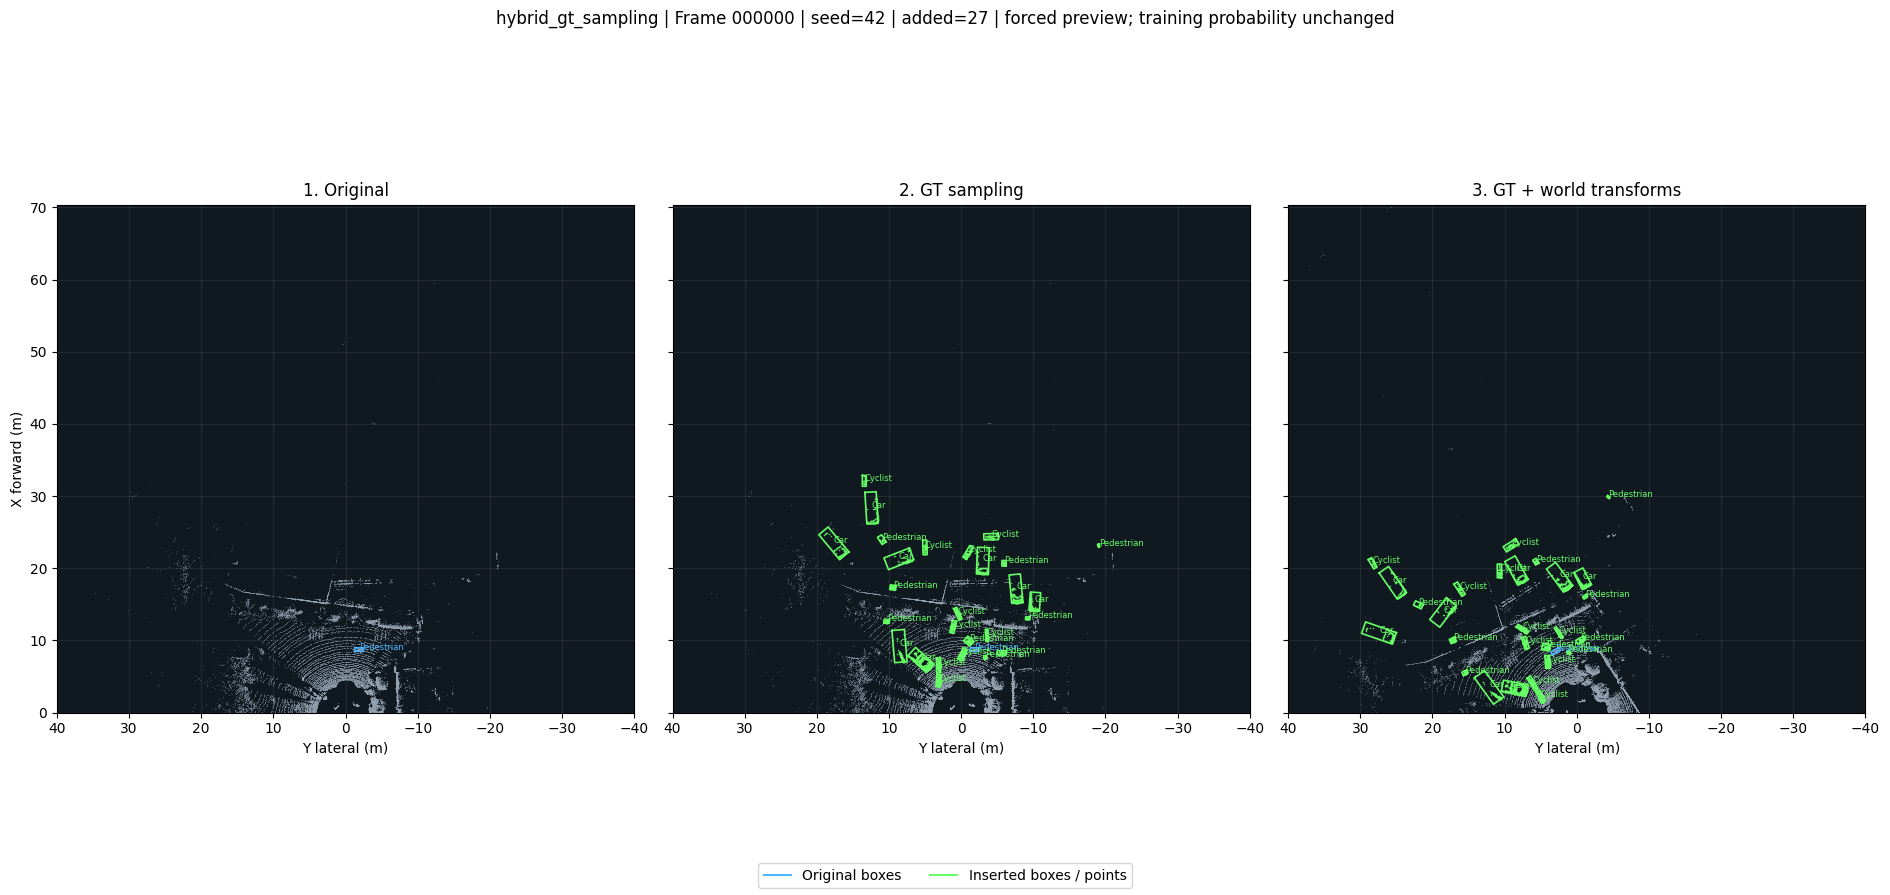

✓ Saved preview figure to: /content/drive/MyDrive/lidar_project/artifacts/mobilepixornext-hybrid_gt_aug-oga_loss-hist14-iqa-head_shared-sgfpn-ctx_none_local_none_blocksimam_c3c4c5_f32_detail0_35dd0bd264e0-grouped_c7edf7b876ec-s42-Final_3d-h32/gt_sampling_preview.png


In [ ]:
# ==============================================================================
# Cell 6: Visualize GT Sampling (Original vs Sampled vs Transformed)
# ==============================================================================
ENABLE_GT_VISUALIZATION = True
FRAME_INDEX = 0             # Chỉ số frame trong train.txt để xem
VISUALIZATION_SEED = 42
FORCE_SAMPLING = True       # Ép buộc chèn mẫu ngay cả khi xác suất ngẫu nhiên < 1

if ENABLE_GT_VISUALIZATION and AUGMENTATION in ("hybrid_gt", "openpcdet_gt"):
    from tools.visualization.visualize_gt_sampling import preview_sampling, render_preview, print_summary
    import matplotlib.pyplot as plt

    print(f"Generating preview for frame index {FRAME_INDEX} with {AUGMENTATION}...")
    try:
        preview = preview_sampling(
            config_dict,
            repo_dir=REPO_DIR,
            frame_index=FRAME_INDEX,
            seed=VISUALIZATION_SEED,
            force_sampling=FORCE_SAMPLING
        )
        print_summary(preview)

        fig = render_preview(preview, config_dict)
        plt.show()

        preview_save_path = RUN_DIR / "gt_sampling_preview.png"
        fig.savefig(preview_save_path, dpi=140)
        print(f"✓ Saved preview figure to: {preview_save_path}")
    except Exception as e:
        print(f"Could not render preview: {e}")
else:
    print("GT Visualization is disabled or current augmentation mode does not use GT database.")

## 🧪 7. Sanity Smoke Train (Kiểm tra nhanh tính toàn vẹn)

Chạy thử 1 epoch cực ngắn (chỉ 2 batch train và 2 batch val) trên thư mục tạm.
Giúp kiểm tra:
- Khả năng forward và backward của mô hình trên GPU.
- Tính hữu hạn của các thành phần loss (không bị NaN / Inf).
- Cập nhật trọng số của optimizer.
👉 Tiết kiệm thời gian, đảm bảo cấu hình chạy trơn tru trước khi bắt đầu Full Training.

In [ ]:
# ==============================================================================
# Cell 7: Fast Sanity Smoke Train
# ==============================================================================
import json
import math
import shutil
import sys
import tempfile
from pathlib import Path
from shlex import quote as q

try:
    from common import create_experiment_config, write_json
except ImportError:
    from tools.kitti_training_pipeline.common import create_experiment_config, write_json

RUN_SMOKE_TEST = True
SMOKE_TRAIN_BATCHES = 2
SMOKE_VAL_BATCHES = 2

if RUN_SMOKE_TEST:
    print("Initiating Sanity Smoke Test...")
    smoke_dir = Path(tempfile.mkdtemp(prefix="smoke_lidar_"))
    smoke_config = create_experiment_config(config_dict, {
        "train": {
            "epochs": 1,
            "warmup_epochs": 0,
            "checkpoint_selection": {"primary": "loss"}
        }
    })
    smoke_cfg_path = smoke_dir / "config.json"
    write_json(smoke_cfg_path, smoke_config)

    !{q(sys.executable)} -u tools/kitti_training_pipeline/train.py --config {q(str(smoke_cfg_path))} --detector-root detector --output-root {q(str(smoke_dir))} --run-name smoke --device {q(DEVICE)} --max-train-batches {SMOKE_TRAIN_BATCHES} --max-val-batches {SMOKE_VAL_BATCHES}

    if _exit_code != 0:
        raise RuntimeError("Smoke test failed! Review trace above.")

    smoke_metric_file = smoke_dir / "smoke/metrics.jsonl"
    smoke_ckpt = smoke_dir / "smoke/checkpoints/last.pt"
    if smoke_metric_file.is_file() and smoke_ckpt.is_file():
        metrics = [json.loads(line) for line in smoke_metric_file.read_text().splitlines() if line.strip()]
        if metrics and math.isfinite(metrics[0]["train_objective"]) and math.isfinite(metrics[0]["validation"]["loss"]):
            print(f"✅ Smoke Test PASSED! Train Objective: {metrics[0]['train_objective']:.4f} | Val Loss: {metrics[0]['validation']['loss']:.4f}")
        else:
            raise RuntimeError("Smoke test finished with non-finite loss.")
    shutil.rmtree(smoke_dir, ignore_errors=True)
else:
    print("Smoke test skipped.")


Initiating Sanity Smoke Test...
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Run directory: /tmp/smoke_lidar__py6vz2a/smoke
I0000 00:00:1792400966.374352   11009 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792400970.453911   11009 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
TensorBoard dir

## 📈 8. TensorBoard Telemetry

Theo dõi đường cong loss thành phần, learning rate, peak VRAM và các chỉ số validation AP theo thời gian thực.

## 🚀 9. Full Training & Smart Auto-Resume (Huấn luyện chính thức)

Bắt đầu huấn luyện mô hình.
- **Tự động Resume**: Nếu bị ngắt kết nối hoặc Colab timeout, chỉ cần chạy lại cell này để tự động tìm checkpoint mới nhất (`last.pt` hoặc `{N}epoch.pt`) và tiếp tục huấn luyện.
- **Dual Checkpoint Retention**: Tự động lưu độc lập **`best_ap_checkpoint.pth`** và **`best_loss_checkpoint.pth`**.
- In tóm tắt Loss & LR trước mỗi vòng tính AP để loại bỏ hiện tượng treo màn hình.

In [ ]:
# ==============================================================================
# Cell 9: Full Training & Smart Auto-Resume
# ==============================================================================
import re
import hashlib
import torch
from pathlib import Path
from shlex import quote as q
try:
    from common import read_json, write_json
except ImportError:
    from tools.kitti_training_pipeline.common import read_json, write_json

CHECKPOINT_DIR = RUN_DIR / "checkpoints"
RUN_METADATA_PATH = RUN_DIR / "run.json"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


RUN_METADATA = {
    "variant": VARIANT,
    "run_name": RUN_NAME,
    "config_sha256": hashlib.sha256(CONFIG.read_bytes()).hexdigest(),
    "seed": SEED,
    "precision": PRECISION,
    "physical_batch_size": PHYSICAL_BATCH_SIZE,
    "accumulation_steps": ACCUMULATION_STEPS,
    "target_backend": TARGET_BACKEND,
    "epochs": EPOCHS,
}

if RUN_METADATA_PATH.is_file():
    saved_meta = read_json(RUN_METADATA_PATH)
    critical = ["config_sha256", "seed", "precision", "physical_batch_size"]
    diffs = [k for k in critical if saved_meta.get(k) != RUN_METADATA.get(k)]
    if diffs:
        print(f"⚠️ Warning: Config differs from previous run on keys: {diffs}")
write_json(RUN_METADATA_PATH, RUN_METADATA)

def get_checkpoint_epoch(path):
    st = torch.load(path, map_location="cpu", weights_only=True)
    return int(st["epoch"])

last_ckpt = CHECKPOINT_DIR / "last.pt"
epoch_ckpts = [p for p in CHECKPOINT_DIR.glob("*epoch.pt") if re.fullmatch(r"\d+epoch\.pt", p.name)]
resume_ckpt = last_ckpt if last_ckpt.is_file() else max(epoch_ckpts, key=get_checkpoint_epoch, default=None)
start_epoch = get_checkpoint_epoch(resume_ckpt) if resume_ckpt else 0

if start_epoch >= EPOCHS:
    print(f"Training already completed: {start_epoch}/{EPOCHS} epochs.")
else:
    resume_arg = f"--resume {q(str(resume_ckpt))}" if resume_ckpt else ""
    print(f"🚀 Starting training run: {RUN_NAME}")
    print(f"Epoch progress: {start_epoch + 1} -> {EPOCHS}")
    print(f"Logs: {RUN_DIR / 'train.log'}")
    print(f"Checkpoints dir: {CHECKPOINT_DIR}")

    !{q(sys.executable)} -u tools/kitti_training_pipeline/train.py --config {q(str(CONFIG))} --detector-root detector --output-root {q(str(ARTIFACT_ROOT))} --run-name {q(RUN_NAME)} --device {q(DEVICE)} {resume_arg}

    if _exit_code != 0:
        raise RuntimeError("Training failed. Review train.log and outputs above.")
    print(f"✓ Training finished! Artifacts stored in {RUN_DIR}")


## 🏆 10. Đánh giá Checkpoint Kép (`best_ap` & `best_loss`)

Đánh giá và so sánh độc lập cả 2 model tốt nhất:
1. **Best AP Checkpoint**: Model có điểm AP cao nhất trên tập validation.
2. **Best Loss Checkpoint**: Model có tổng validation loss nhỏ nhất.

Bảng kết quả sẽ hiển thị chi tiết AP từng lớp (`Car`, `Pedestrian`, `Cyclist`), Mean Moderate AP và Validation Loss.

In [ ]:
# ==============================================================================
# Cell 10: Dual Checkpoint Evaluation (Best AP & Best Loss) - Hỗ trợ Early Stopping
# ==============================================================================
import gc
import json
import torch
import pandas as pd
from pathlib import Path
from IPython.display import display
from tools.kitti_training_pipeline import notebook_workflow
from tools.kitti_training_pipeline.common import read_json, write_json
from tools.kitti_training_pipeline.notebook_workflow import evaluation_rows

RUN_EVALUATION = True

def get_evaluated_runs_safe(run_dir):
    """Lấy danh sách checkpoint để evaluate, tự động fallback nếu train bị dừng sớm."""
    try:
        # Cách chuẩn: chỉ pass khi train hoàn thành 100% số epochs đã cấu hình
        return notebook_workflow.selected_runs(run_dir)
    except Exception as err:
        print(f"⚠️ Phát hiện train chưa chạy hết epochs ({err}).")
        print("🔄 Chuyển sang chế độ Early-Stopping Fallback (đọc trực tiếp checkpoint đã lưu)...")

        root = Path(run_dir).expanduser().resolve()
        config_path = root / 'config.resolved.json'
        config = read_json(config_path)
        selected_dir = root / 'selected'

        runs = {}
        for kind in ('ap', 'loss'):
            ckpt_path = selected_dir / f'best_{kind}.pt'
            if not ckpt_path.is_file():
                if kind == 'ap' and (selected_dir / 'best.pt').is_file():
                    ckpt_path = selected_dir / 'best.pt'
                else:
                    continue

            # Đọc metadata từ checkpoint đã lưu
            saved = torch.load(ckpt_path, map_location='cpu', weights_only=False)
            val_loss = saved.get('validation', {}).get('loss', 0.0)
            epoch = saved.get('epoch', 0)

            runs[kind] = {
                'run_dir': root,
                'config_path': config_path,
                'config': config,
                'checkpoint': ckpt_path,
                'selection_path': selected_dir / f'selection_{kind}.json',
                'history_path': root / 'metrics.jsonl',
                'completed_epochs': epoch,
                'selection_kind': kind,
                'epoch': epoch,
                'validation_loss': val_loss,
                'is_primary': (kind == 'ap')
            }

        if not runs:
            raise FileNotFoundError(f"Không tìm thấy checkpoint hợp lệ nào trong {selected_dir}!")
        return runs

if RUN_EVALUATION:
    # 1. Giải phóng VRAM nếu vừa ngắt tiến trình training
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"Evaluating best winners for run: {RUN_NAME}...")
    evaluated_runs = get_evaluated_runs_safe(RUN_DIR)
    comparison_rows = []

    for kind, evaluated_run in evaluated_runs.items():
        print(f"\n=======================================================")
        print(f"🔍 Evaluating '{kind.upper()}' checkpoint (Epoch {evaluated_run['epoch']})")
        print(f"=======================================================")
        for mode in EVALUATION_MODES:
            output_json = RUN_DIR / f"evaluation_{kind}_{mode}.json"
            raw_root = globals().get("RAW_KITTI_ROOT") or (globals().get("RAW_TRAINING").parent if "RAW_TRAINING" in globals() else Path("/content/kitti_raw"))
            cmd_args = notebook_workflow.evaluation_command(
                evaluated_run,
                mode,
                raw_root,
                output_json,
                repo_root=REPO_DIR,
                device=DEVICE
            )
            cmd_args.insert(1, "-u")
            eval_cmd = " ".join(q(str(a)) for a in cmd_args)

            !{eval_cmd}
            if _exit_code != 0:
                raise RuntimeError(f"Evaluation failed for {kind} in mode {mode}")

            report = read_json(output_json)
            rows = evaluation_rows(report, selection_kind=kind)
            for row in rows:
                row["checkpoint_winner"] = kind
                row["best_epoch"] = evaluated_run["epoch"]
                row["val_loss"] = evaluated_run["validation_loss"]
            comparison_rows.extend(rows)

    if comparison_rows:
        df_comparison = pd.DataFrame(comparison_rows)
        print("\n" + "=" * 80)
        print("🏆 EVALUATION SUMMARY (BEST AP vs BEST LOSS)")
        print("=" * 80)
        display(df_comparison)

        csv_path = RUN_DIR / "comparison_best_ap_vs_loss.csv"
        df_comparison.to_csv(csv_path, index=False)
        write_json(RUN_DIR / "comparison_best_ap_vs_loss.json", {"rows":
comparison_rows})
        print(f"✓ Summary saved to: {csv_path}")


## 🔍 11. Đánh giá Checkpoint của Run khác (Tùy chọn)

Nếu bạn có một run huấn luyện khác trong `artifacts` muốn đánh giá lại hoặc so sánh, chỉ cần đặt đường dẫn thư mục vào biến `EXTERNAL_RUN_DIR`.


In [ ]:
# ==============================================================================
# Cell 11: Evaluate External Run (Optional)
# ==============================================================================
EXTERNAL_RUN_DIR = None  # Ví dụ: ARTIFACT_ROOT / "ten_run_khac"

if EXTERNAL_RUN_DIR and Path(EXTERNAL_RUN_DIR).is_dir():
    ext_path = Path(EXTERNAL_RUN_DIR)
    print(f"Evaluating external run: {ext_path}")
    ext_runs = notebook_workflow.selected_runs(ext_path)
    ext_rows = []
    for kind, ext_run in ext_runs.items():
        for mode in ext_run["config"].get("evaluation", {}).get("modes", ["local_bev"]):
            out_file = ext_path / f"standalone_eval_{kind}_{mode}.json"
            raw_root = ext_run["config"].get("evaluation", {}).get("kitti_root", RAW_KITTI_ROOT)
            args = notebook_workflow.evaluation_command(ext_run, mode, raw_root, out_file, repo_root=REPO_DIR, device=DEVICE)
            args.insert(1, "-u")
            !{" ".join(q(str(a)) for a in args)}
            if _exit_code == 0:
                ext_rows.extend(evaluation_rows(read_json(out_file), selection_kind=kind))
    if ext_rows:
        display(pd.DataFrame(ext_rows))
else:
    print("No external run specified. Set EXTERNAL_RUN_DIR to evaluate an existing run.")
